**Before running this notebook:**

1. Download the data: `uv run python -m ev_gap.download`
2. Run the data pipeline: `uv run python -m ev_gap.pipeline`
3. Run the model: `uv run python -m ev_gap.model`. This notebook reads its output (`data/processed/gaps.csv`).
4. Select the kernel of the `.venv` in this folder.

# Ranking of the districts and a rough value estimate

The model gives every district an expected number of public charging points and a gap in percent. This notebook turns the gaps into a ranked list and puts a rough value on closing them.

**How to read the result.** The gap says how far a district is from what typical districts of its size have. It does not say how many charging points are optimal, and it does not say that a district needs more. The typical model error is about 21%. A district is called **clearly below** if it has more than 30% fewer charging points than expected. Gaps between -30% and 0% are within the noise.

**The value estimate is built from assumptions.** Each one is listed in section 5 with its source, or with the note that it is a guess. The result is an order of magnitude, not a business case. It ignores the cost of electricity, operation, site rent and tax.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ev_gap import config
from ev_gap.extract import read_register
from ev_gap.pipeline import load_districts
from ev_gap.ranking import CASES, estimate_value, load_gaps, rank_districts

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (9, 5.5), "axes.spines.top": False, "axes.spines.right": False})

districts = load_districts()
ranking = rank_districts(load_gaps())
below = ranking[ranking["clearly_below"]]
print(len(ranking), "districts |", len(below), "clearly below expected (more than 30% fewer points) |",
      int(ranking["robust"].sum()), "of them robust (gradient boosting agrees)")

399 districts | 55 clearly below expected (more than 30% fewer points) | 42 of them robust (gradient boosting agrees)


## 1. Ranking by percent gap

Where is the lag largest compared with the district's own size? The dark bars are **robust**: the linear model and gradient boosting both put the district more than 30% below expected.

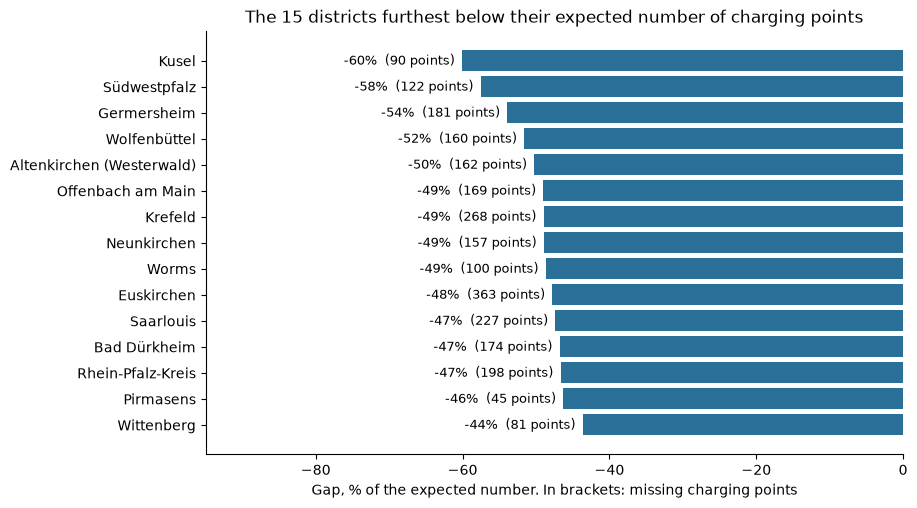

 rank_pct                        name               state  actual  expected  gap_pct  missing_points  robust
        1                       Kusel     Rheinland-Pfalz      60     150.0    -60.0            90.0    True
        2                Südwestpfalz     Rheinland-Pfalz      90     212.0    -58.0           122.0    True
        3                 Germersheim     Rheinland-Pfalz     155     336.0    -54.0           181.0    True
        4                Wolfenbüttel       Niedersachsen     150     310.0    -52.0           160.0    True
        5   Altenkirchen (Westerwald)     Rheinland-Pfalz     161     323.0    -50.0           162.0    True
        6    Offenbach am Main, Stadt              Hessen     176     345.0    -49.0           169.0    True
        7              Krefeld, Stadt Nordrhein-Westfalen     280     548.0    -49.0           268.0    True
        8                 Neunkirchen            Saarland     164     321.0    -49.0           157.0    True
        9     Worms

In [2]:
top_pct = ranking.nsmallest(15, "gap_pct")
fig, ax = plt.subplots()
labels = top_pct["name"].str.replace(", kreisfreie Stadt", "").str.replace(", Stadt", "")
colors = ["#2a6f97" if r else "#8fb8d4" for r in top_pct["robust"]]
ax.barh(labels[::-1], top_pct["gap_pct"][::-1], color=colors[::-1])
for y, (gap, missing) in enumerate(zip(top_pct["gap_pct"][::-1], top_pct["missing_points"][::-1])):
    ax.text(gap - 1, y, f"{gap:.0f}%  ({missing:.0f} points)", va="center", ha="right", fontsize=9)
ax.set_xlim(-95, 0)
ax.set_xlabel("Gap, % of the expected number. In brackets: missing charging points")
ax.set_title("The 15 districts furthest below their expected number of charging points")
plt.show()

show = ["rank_pct", "name", "state", "actual", "expected", "gap_pct", "missing_points", "robust"]
print(top_pct[show].round(0).to_string(index=False))

Sorting by percent favours small districts. Kusel is at -60%, but that is 90 missing charging points. A few of the districts on this list are small, so a percentage can hide how little it means in absolute terms.

## 2. Ranking by missing charging points

Where is the largest shortfall in absolute terms? This is the more useful view for someone who wants to invest. Missing points = expected minus actual.

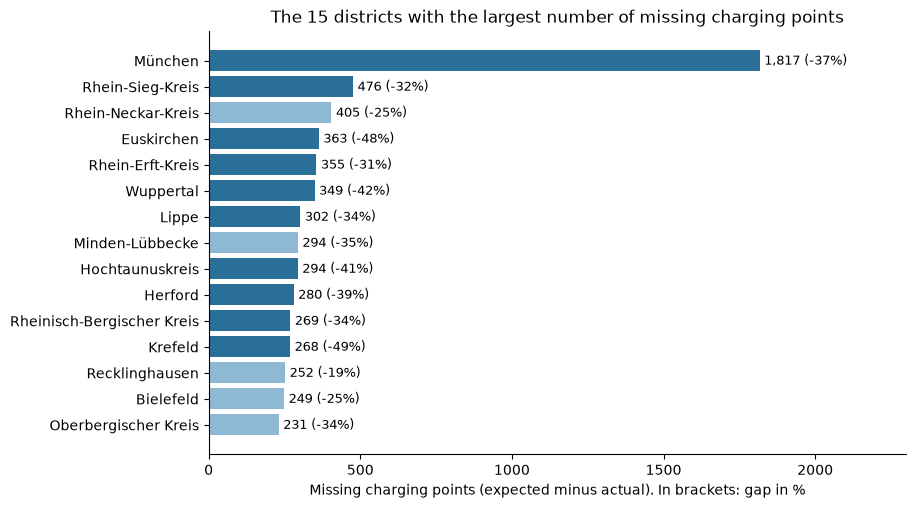

districts that are in both top 15 lists: 2
München: gap -37 %, rank by percent 30 , rank by missing points 1


In [3]:
top_points = ranking.nsmallest(15, "rank_points")
top_points = top_points.assign(label=top_points["gap_pct"].round(0).astype(int).astype(str) + "%")
fig, ax = plt.subplots()
labels = top_points["name"].str.replace(", Landeshauptstadt", "").str.replace(", Stadt", "")
colors = ["#2a6f97" if r else "#8fb8d4" for r in top_points["robust"]]
ax.barh(labels[::-1], top_points["missing_points"][::-1], color=colors[::-1])
for y, (value, text) in enumerate(zip(top_points["missing_points"][::-1], top_points["label"][::-1])):
    ax.text(value + 15, y, f"{value:,.0f} ({text})", va="center", fontsize=9)
ax.set_xlim(0, 2300)
ax.set_xlabel("Missing charging points (expected minus actual). In brackets: gap in %")
ax.set_title("The 15 districts with the largest number of missing charging points")
plt.show()

same = len(set(top_pct["key"]) & set(top_points["key"]))
print("districts that are in both top 15 lists:", same)
print("München: gap", round(ranking.set_index("name").loc["München, Landeshauptstadt", "gap_pct"]), "%, rank by percent",
      int(ranking.set_index("name").loc["München, Landeshauptstadt", "rank_pct"]), ", rank by missing points",
      int(ranking.set_index("name").loc["München, Landeshauptstadt", "rank_points"]))

**The two rankings answer different questions.** Only 2 of the 15 districts at the top by percent are also in the top 15 by missing points. The percent view finds small districts in Rheinland-Pfalz and Saarland. The absolute view finds large districts, mostly in Nordrhein-Westfalen, and Munich: 37% below expected is only rank 30 by percent, but it is the largest shortfall in Germany in absolute terms. Which view fits depends on who reads it. A municipality asking where it lags behind its peers looks at percent. An operator choosing where to build looks at points.

## 3. Who is on the list?

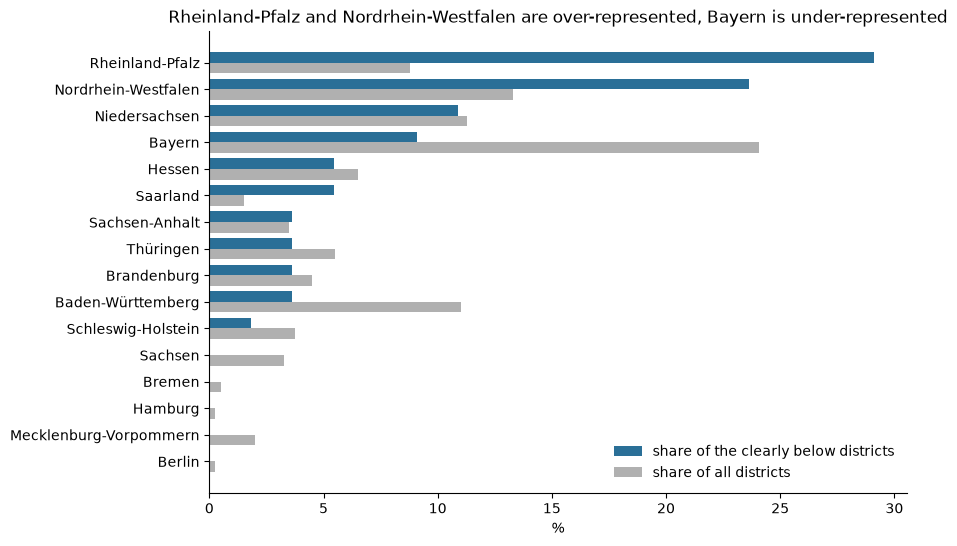

Rheinland-Pfalz and Saarland: 35% of the clearly below districts, 10% of all districts
The 55 clearly below districts have 10,415,231 residents and 277,593 BEV (13.7% of all BEV)


In [4]:
by_state = pd.DataFrame({
    "districts in the state": ranking["state"].value_counts(),
    "clearly below": below["state"].value_counts(),
}).fillna(0).astype(int)
by_state["share of all districts"] = by_state["districts in the state"] / len(ranking)
by_state["share of clearly below"] = by_state["clearly below"] / len(below)
by_state = by_state.sort_values("share of clearly below", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
positions = np.arange(len(by_state))
ax.barh(positions + 0.2, by_state["share of clearly below"] * 100, 0.4, color="#2a6f97", label="share of the clearly below districts")
ax.barh(positions - 0.2, by_state["share of all districts"] * 100, 0.4, color="#b0b0b0", label="share of all districts")
ax.set_yticks(positions, by_state.index)
ax.set_xlabel("%")
ax.set_title("Rheinland-Pfalz and Nordrhein-Westfalen are over-represented, Bayern is under-represented")
ax.legend(frameon=False, loc="lower right")
plt.show()

rp_saar = below["state"].isin(["Rheinland-Pfalz", "Saarland"]).mean()
rp_saar_all = ranking["state"].isin(["Rheinland-Pfalz", "Saarland"]).mean()
print(f"Rheinland-Pfalz and Saarland: {rp_saar:.0%} of the clearly below districts, {rp_saar_all:.0%} of all districts")
print(f"The {len(below)} clearly below districts have {below['population'].sum():,.0f} residents and {below['bev'].sum():,.0f} BEV",
      f"({below['bev'].sum() / ranking['bev'].sum():.1%} of all BEV)")

The model does not know the federal state, so state-wide patterns end up in the gaps (see the model notebook). Many entries from Rheinland-Pfalz and Saarland say something about those two states, not necessarily about each district.

## 4. How big is the gap, compared with what is built anyway?

From observed data only, no assumptions: how many charging points were commissioned per year, according to the register? Only stations that are still in the register are counted, and 2026 is incomplete (until 12 November).

In [5]:
register = read_register(next(config.RAW_DIR.glob(config.BNETZA_GLOB)))
register = register[register["status"] == config.ACTIVE_STATUS]
built = register.groupby(register["commissioned"].dt.year)["n_points"].sum().loc[2021:2026]
print(built.to_string())

missing_band = below["missing_to_band"].sum()
missing_expected = below["missing_to_expected"].sum()
print()
print(f"missing points in the {len(below)} clearly below districts:")
print(f"  to the edge of the band (70% of expected): {missing_band:,.0f}  =  {missing_band / built.loc[2025] * 12:.1f} months of the 2025 build rate")
print(f"  to the expected number:                    {missing_expected:,.0f}  =  {missing_expected / built.loc[2025] * 12:.1f} months of the 2025 build rate")

commissioned
2021    16840
2022    27290
2023    41095
2024    36194
2025    35754
2026    23258

missing points in the 55 clearly below districts:
  to the edge of the band (70% of expected): 2,278  =  0.8 months of the 2025 build rate
  to the expected number:                    10,423  =  3.5 months of the 2025 build rate


Closing the gap of the clearly below districts to the edge of the band would be less than one month of the national build rate of 2025. Closing it to the expected number would be about three and a half months. The gap is large for each district, but small compared with what the market builds in a year.

## 5. Value estimate

### Assumptions

Every number is an assumption, even where a source is named. Low, base and high are used together: the low estimate takes the low values of all assumptions, the high estimate the high values.

In [6]:
fast_share = districts["points_fast"].sum() / districts["charging_points"].sum()
rows = [
    ("Share of fast chargers among new points", f"{fast_share:.1%}", "observed: share of fast charging points in the register, applied to the new points (assumption: same mix)"),
    ("Investment per normal point, EUR", " / ".join(f"{config.COST_PER_POINT_EUR['normal'][c]:,}" for c in CASES), "Oeko-Institut, EWI, FCN 22.07.2022, table 2-1: 22 kW public, 2.5-4.5k hardware + 1.5-3k installation. Without VAT, grid expansion"),
    ("Investment per fast point, EUR", " / ".join(f"{config.COST_PER_POINT_EUR['fast'][c]:,}" for c in CASES), "same table: 50 kW public 23-32k. The high value is the lower bound of the 150 kW class (65k). Prices of 2021/22, not updated"),
    ("Sessions per point and day (normal / fast)", f"{config.SESSIONS_PER_DAY['normal']} / {config.SESSIONS_PER_DAY['fast']}", "national average 2025, seen in a search summary of a Statista page, not opened. Unverified"),
    ("Use of new points, share of the average", " / ".join(str(config.UTILIZATION_FACTOR[c]) for c in CASES), "pure assumption"),
    ("Energy per session, kWh (normal)", " / ".join(str(config.KWH_PER_SESSION['normal'][c]) for c in CASES), "pure assumption"),
    ("Energy per session, kWh (fast)", " / ".join(str(config.KWH_PER_SESSION['fast'][c]) for c in CASES), "pure assumption"),
    ("Ad hoc price, ct per kWh (normal / fast)", f"{config.AD_HOC_PRICE_CT_PER_KWH['normal']} / {config.AD_HOC_PRICE_CT_PER_KWH['fast']}", "average ad hoc prices, July 2026, ACE and Hocsy (AC and DC), via a search summary"),
    ("Price factor (share of the ad hoc price paid)", " / ".join(str(config.PRICE_FACTOR[c]) for c in CASES), "pure assumption, because many drivers pay less with a contract"),
]
print(pd.DataFrame(rows, columns=["assumption", "low / base / high", "source or status"]).to_string(index=False))

                                   assumption        low / base / high                                                                                                                  source or status
      Share of fast chargers among new points                    28.5%                         observed: share of fast charging points in the register, applied to the new points (assumption: same mix)
             Investment per normal point, EUR    4,000 / 5,750 / 7,500 Oeko-Institut, EWI, FCN 22.07.2022, table 2-1: 22 kW public, 2.5-4.5k hardware + 1.5-3k installation. Without VAT, grid expansion
               Investment per fast point, EUR 23,000 / 27,500 / 65,000      same table: 50 kW public 23-32k. The high value is the lower bound of the 150 kW class (65k). Prices of 2021/22, not updated
   Sessions per point and day (normal / fast)               0.63 / 2.5                                        national average 2025, seen in a search summary of a Statista page, not opened. Unveri

**What the value includes and leaves out.** Investment is hardware plus planning and installation of the charging point. It leaves out grid expansion, battery storage, VAT and subsidies. Revenue is **gross**: price times energy. The cost of electricity, operation (the study gives 300 to 800 EUR per point and year), site rent, payment fees and tax are not subtracted. It is not profit. No margin is assumed, because none could be sourced.

In [7]:
value = estimate_value(ranking, fast_share)
table = value.assign(
    investment_million_eur=(value["investment_eur"] / 1e6).round(0),
    gross_revenue_million_eur_per_year=(value["gross_revenue_eur_per_year"] / 1e6).round(0),
    missing_points=value["missing_points"].round(0),
).drop(columns=["investment_eur", "gross_revenue_eur_per_year"])
print(table.to_string(index=False))

               coverage case  districts  missing_points  investment_million_eur  gross_revenue_million_eur_per_year
to the edge of the band  low         55          2278.0                    21.0                                 4.0
to the edge of the band base         55          2278.0                    27.0                                11.0
to the edge of the band high         55          2278.0                    54.0                                23.0
            to expected  low         55         10423.0                    98.0                                20.0
            to expected base         55         10423.0                   125.0                                51.0
            to expected high         55         10423.0                   249.0                               104.0


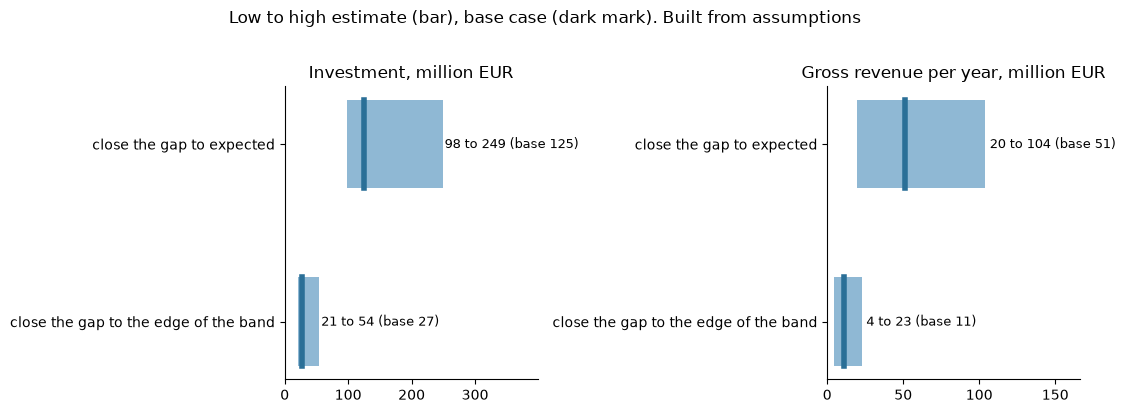

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, title in zip(axes, ["investment_eur", "gross_revenue_eur_per_year"],
                             ["Investment, million EUR", "Gross revenue per year, million EUR"]):
    for y, coverage in enumerate(config.COVERAGES):
        part = value[value["coverage"] == coverage].set_index("case")[column] / 1e6
        ax.barh(y, part["high"] - part["low"], left=part["low"], height=0.5, color="#8fb8d4")
        ax.plot([part["base"]] * 2, [y - 0.25, y + 0.25], color="#2a6f97", linewidth=4)
        ax.text(part["high"] + 3, y, f"{part['low']:.0f} to {part['high']:.0f} (base {part['base']:.0f})", va="center", fontsize=9)
    ax.set_yticks(range(len(config.COVERAGES)), [f"close the gap {c}" for c in config.COVERAGES])
    ax.set_xlim(0, value[column].max() / 1e6 * 1.6)
    ax.set_title(title)
fig.suptitle("Low to high estimate (bar), base case (dark mark). Built from assumptions", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
base = value[value["case"] == "base"].set_index("coverage")
per_point_cost = base.loc["to expected", "investment_eur"] / base.loc["to expected", "missing_points"]
per_point_revenue = base.loc["to expected", "gross_revenue_eur_per_year"] / base.loc["to expected", "missing_points"]
print(f"base case per new point: investment {per_point_cost:,.0f} EUR, gross revenue {per_point_revenue:,.0f} EUR per year")
print(f"for scale: the {built.loc[2025]:,} points built in 2025 would cost {built.loc[2025] * per_point_cost / 1e6:,.0f} million EUR at this base cost per point")

base case per new point: investment 11,950 EUR, gross revenue 4,914 EUR per year
for scale: the 35,754 points built in 2025 would cost 427 million EUR at this base cost per point


**Reading the estimate**

- Closing the gaps of the 55 clearly below districts to the **edge of the band** needs about 2,300 charging points. The investment is about 27 million EUR in the base case (21 to 54 million EUR). The gross revenue is about 11 million EUR per year (4 to 23 million EUR).
- Closing the gaps **to the expected number** needs about 10,400 points. The investment is about 125 million EUR (98 to 249 million EUR). The gross revenue is about 51 million EUR per year (20 to 104 million EUR).
- The range is wide, because the assumptions are wide. Investment depends mostly on how many of the new points are fast chargers and how powerful they are. Revenue depends mostly on how much the new points are used, which is a guess.
- The investment is probably a lower bound. The study excludes grid connection and storage, and the base case uses 50 kW fast chargers, while many new fast chargers are stronger.
- The revenue is before electricity and operating cost. It must not be read as profit.
- It is not known whether the new points would be used as much as assumed. A district can be below its expected number for good reasons, such as low demand or home charging. Utilization data from operators is the missing piece, and it would be the first step towards a real business case.